# DS-471 Machine Learning Project — Breast Cancer Classification

**Dataset:** UCI Breast Cancer Wisconsin (Diagnostic) — https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic
(the same 569-sample dataset is shipped with scikit-learn as `load_breast_cancer`, so the notebook runs without a download).

**Goal:** predict whether a breast mass is **malignant** or **benign** from 30 numeric features computed from a digitized image of a fine-needle aspirate (FNA).

Workflow: 1) data cleaning, preparation & EDA → 2) train/validation/test split → 3) model selection → 4) training & hyperparameter tuning → 5) final evaluation & comparison.

In [1]:
import os, warnings
os.environ["PYTHONWARNINGS"] = "ignore"  # also silences deprecation warnings inside parallel CV workers
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, learning_curve, validation_curve
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, log_loss, classification_report)
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
np.random.seed(SEED)
os.makedirs("figures", exist_ok=True)
sns.set_theme(style="whitegrid")
def save(name):
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## Stage 1 — Data Cleaning, Preparation and Exploration
### 1.1 Understanding the dataset

In [2]:
raw = load_breast_cancer(as_frame=True)
df = raw.frame.copy()
# scikit-learn codes 0 = malignant, 1 = benign. We flip it so the positive class (1) is the one we care about: malignant.
df["diagnosis"] = (df["target"] == 0).astype(int)
df = df.drop(columns="target")
print("Shape:", df.shape)
print("Feature dtypes:", df.drop(columns="diagnosis").dtypes.value_counts().to_dict())
df.head()

Shape: (569, 31)
Feature dtypes: {dtype('float64'): 30}


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


In [3]:
# Each of the 10 cell-nucleus measurements is reported 3 ways: mean, standard error, and 'worst' (mean of the 3 largest values)
base = ["radius","texture","perimeter","area","smoothness","compactness","concavity","concave points","symmetry","fractal dimension"]
print("Base measurements:", base)
df.describe().T.round(3)

Base measurements: ['radius', 'texture', 'perimeter', 'area', 'smoothness', 'compactness', 'concavity', 'concave points', 'symmetry', 'fractal dimension']


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean concave points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean symmetry,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean fractal dimension,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


### 1.2 Missing values, duplicates, inconsistent values

In [4]:
print("Missing values in total:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
X_all = df.drop(columns="diagnosis")
print("Negative values (impossible for size/shape measurements):", int((X_all < 0).sum().sum()))
zero_counts = (X_all == 0).sum()
print("Columns containing zeros:\n", zero_counts[zero_counts > 0])

Missing values in total: 0
Duplicate rows: 0
Negative values (impossible for size/shape measurements): 0
Columns containing zeros:
 mean concavity          13
mean concave points     13
concavity error         13
concave points error    13
worst concavity         13
worst concave points    13
dtype: int64


In [5]:
# The zeros appear only in concavity / concave-points columns. Check that they are consistent:
# a nucleus with zero concavity must also have zero concave points.
z = df[(df["mean concavity"] == 0)]
print(len(z), "rows with mean concavity = 0; their mean concave points:", z["mean concave points"].unique())
print("Diagnosis of those rows:", z["diagnosis"].value_counts().to_dict())

13 rows with mean concavity = 0; their mean concave points: [0.]
Diagnosis of those rows: {0: 13}


### 1.3 Outliers

In [6]:
q1, q3 = X_all.quantile(.25), X_all.quantile(.75)
iqr = q3 - q1
out_mask = (X_all < q1 - 1.5*iqr) | (X_all > q3 + 1.5*iqr)
outliers = out_mask.sum().sort_values(ascending=False)
print("Rows with at least one IQR outlier:", int(out_mask.any(axis=1).sum()), "of", len(df))
print("Share of outlier rows that are malignant:", round(df.loc[out_mask.any(axis=1), "diagnosis"].mean(), 3))
outliers.head(10)

Rows with at least one IQR outlier: 171 of 569
Share of outlier rows that are malignant: 0.667


area error                 65
radius error               38
perimeter error            38
worst area                 35
smoothness error           30
fractal dimension error    28
compactness error          28
symmetry error             27
mean area                  25
worst fractal dimension    24
dtype: int64

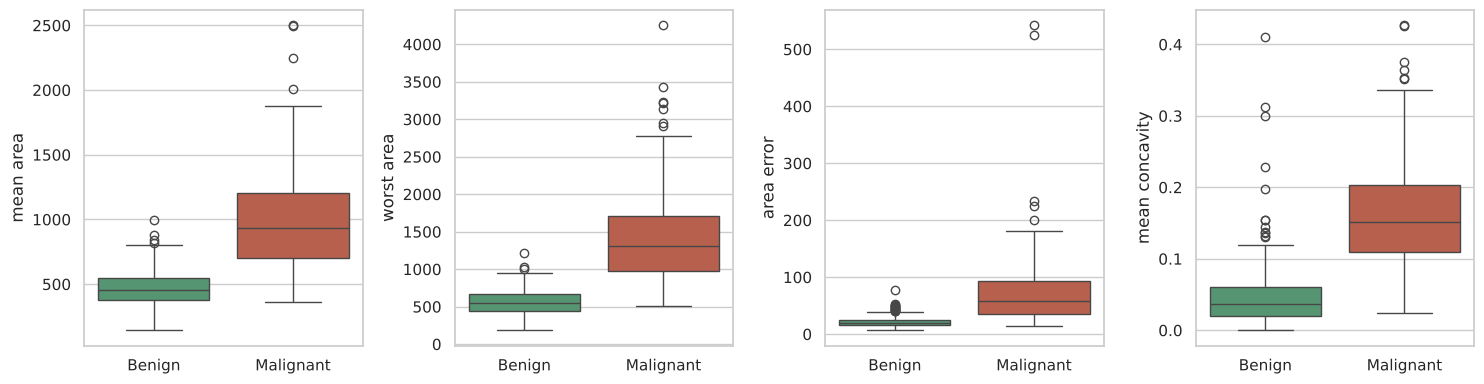

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, col in zip(axes, ["mean area", "worst area", "area error", "mean concavity"]):
    sns.boxplot(data=df, x="diagnosis", y=col, ax=ax, hue="diagnosis", palette=["#4C9F70", "#C8553D"], legend=False)
    ax.set_xticks([0, 1], ["Benign", "Malignant"]); ax.set_xlabel("")
save("01_outlier_boxplots")

### 1.4 Exploratory data analysis — target distribution

{'Benign': 357, 'Malignant': 212} | malignant share: 0.373


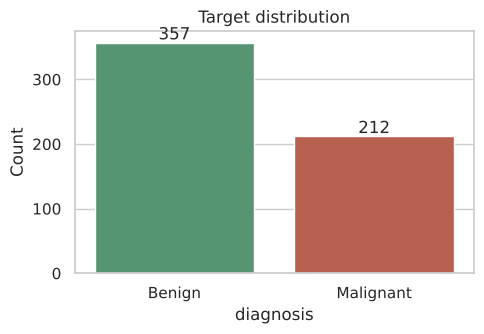

In [8]:
counts = df["diagnosis"].value_counts().rename({0: "Benign", 1: "Malignant"})
print(counts.to_dict(), "| malignant share:", round(df['diagnosis'].mean(), 3))
plt.figure(figsize=(5, 3.5))
ax = sns.barplot(x=counts.index, y=counts.values, hue=counts.index, palette=["#4C9F70", "#C8553D"], legend=False)
for i, v in enumerate(counts.values): ax.text(i, v + 5, str(v), ha="center")
plt.ylabel("Count"); plt.title("Target distribution")
save("02_target_distribution")

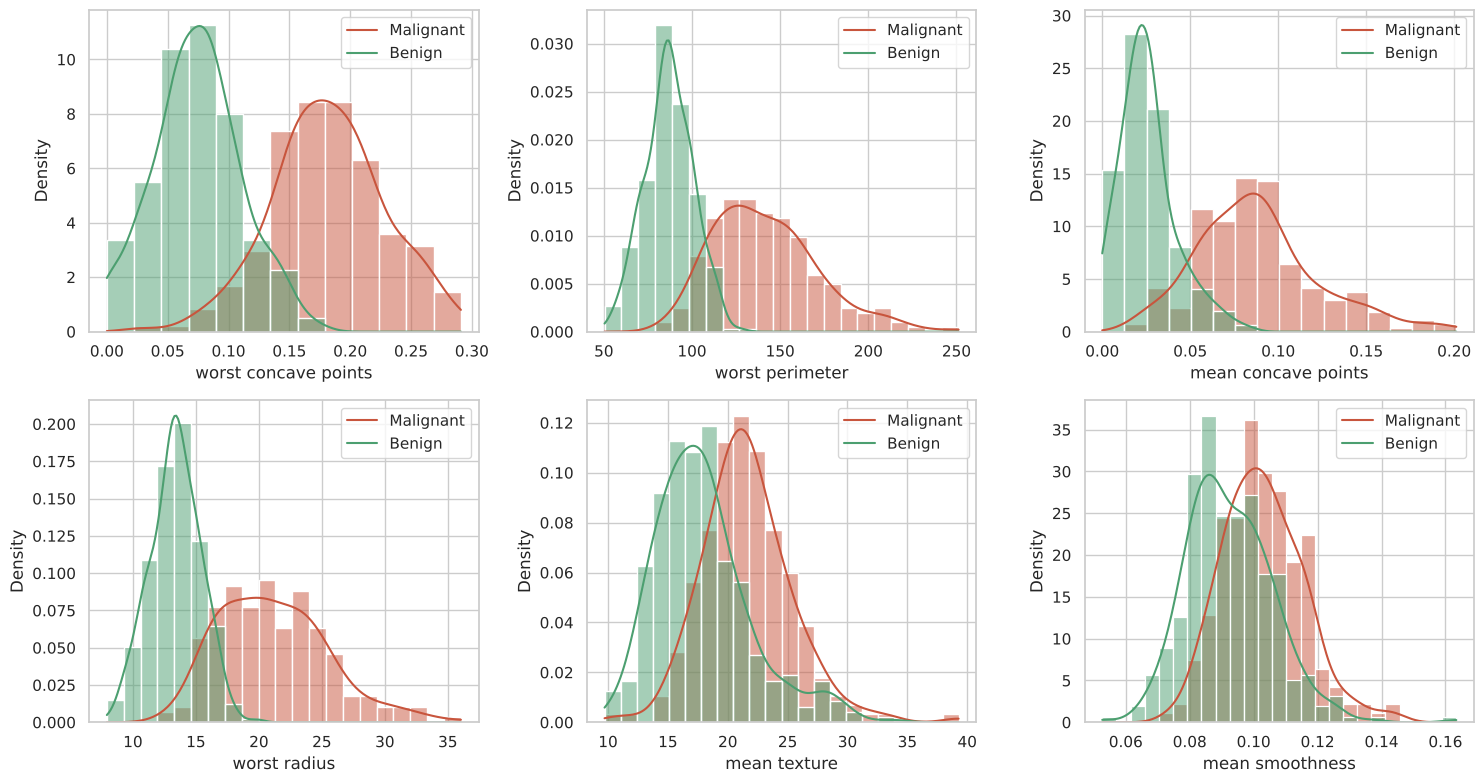

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), ["worst concave points", "worst perimeter", "mean concave points", "worst radius", "mean texture", "mean smoothness"]):
    sns.histplot(data=df, x=col, hue="diagnosis", kde=True, ax=ax, palette=["#4C9F70", "#C8553D"], stat="density", common_norm=False)
    ax.legend(["Malignant", "Benign"])
save("03_feature_distributions_by_class")

In [10]:
skew = X_all.skew().sort_values(ascending=False)
print("Features with |skew| > 1:", int((skew.abs() > 1).sum()))
skew.head(10).round(2)

Features with |skew| > 1: 22


area error                 5.45
concavity error            5.11
fractal dimension error    3.92
perimeter error            3.44
radius error               3.09
smoothness error           2.31
symmetry error             2.20
compactness error          1.90
worst area                 1.86
worst fractal dimension    1.66
dtype: float64

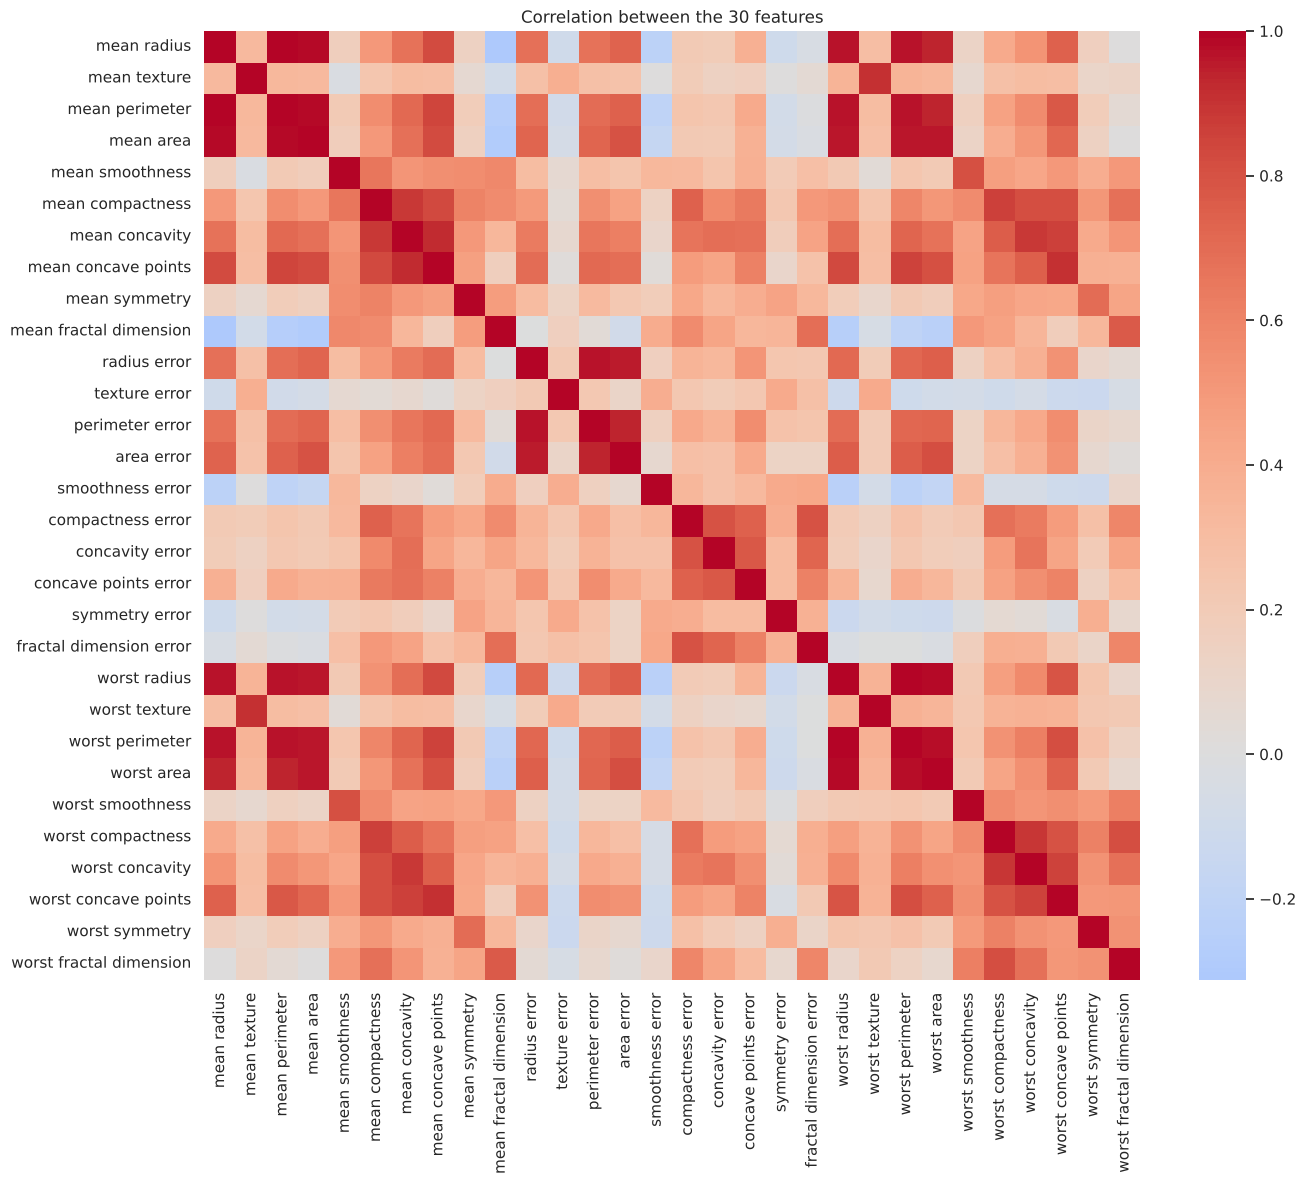

Feature pairs with |r| > 0.95: 15


mean radius      mean perimeter     0.998
worst radius     worst perimeter    0.994
mean radius      mean area          0.987
mean perimeter   mean area          0.987
worst radius     worst area         0.984
worst perimeter  worst area         0.978
radius error     perimeter error    0.973
mean perimeter   worst perimeter    0.970
dtype: float64

In [11]:
plt.figure(figsize=(14, 12))
sns.heatmap(X_all.corr(), cmap="coolwarm", center=0, xticklabels=True, yticklabels=True)
plt.title("Correlation between the 30 features")
save("04_correlation_heatmap")
corr = X_all.corr().abs()
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().sort_values(ascending=False)
print("Feature pairs with |r| > 0.95:", int((pairs > 0.95).sum()))
pairs.head(8).round(3)

### 1.5 Most relevant features

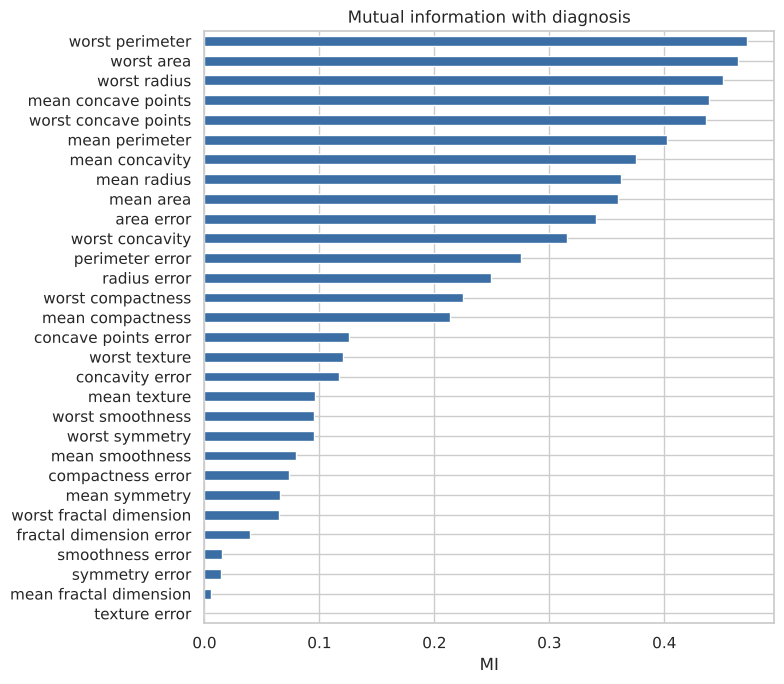

,corr_with_target,mutual_info
worst perimeter,0.783,0.472
worst area,0.734,0.464
worst radius,0.776,0.451
mean concave points,0.777,0.439
worst concave points,0.794,0.436
mean perimeter,0.743,0.402
mean concavity,0.696,0.375
mean radius,0.730,0.362
mean area,0.709,0.360
area error,0.548,0.341


In [12]:
rel = pd.DataFrame({
    "corr_with_target": X_all.corrwith(df["diagnosis"]),
    "mutual_info": mutual_info_classif(X_all, df["diagnosis"], random_state=SEED),
}).sort_values("mutual_info", ascending=False)
fig, ax = plt.subplots(figsize=(8, 7))
rel["mutual_info"].sort_values().plot.barh(ax=ax, color="#3A6EA5")
ax.set_title("Mutual information with diagnosis"); ax.set_xlabel("MI")
save("05_feature_relevance")
rel.head(10).round(3)

### 1.6 Preprocessing and feature engineering decisions
* **No imputation / de-duplication needed** — there are no missing values or duplicate rows. The 13 zero values in concavity columns are consistent (zero concavity ⇒ zero concave points) and are real measurements of smooth nuclei, so they are kept.
* **Outliers are kept.** They are mostly malignant tumours (large, irregular nuclei); removing them would delete the very cases we most need to detect. Their influence is reduced by the log transform and scaling below instead.
* **Log transform (`log1p`)** on strongly right-skewed features (|skew| > 1, chosen on the training set only). This makes the distributions closer to symmetric, which helps the linear model, the SVM kernel distances and the neural network's gradient steps.
* **Correlation filter**: from each pair with |r| > 0.95 one feature is dropped (e.g. perimeter and area are almost a function of radius). Redundant inputs inflate coefficient variance in logistic regression and add noise to distance-based models.
* **Standard scaling** — required by Logistic Regression (regularisation penalises all coefficients equally), SVM (RBF distances) and the NN (stable optimisation).
* **Random Forest uses the raw 30 features**: trees split on thresholds, so they are unaffected by scale or skew and handle correlated inputs.
* **Encoding**: all inputs are numeric; only the target is encoded (malignant = 1, benign = 0).
* All transformations are fitted **inside a scikit-learn Pipeline on the training data only**, so no information from validation/test leaks into preprocessing.

In [13]:
class SkewLog(BaseEstimator, TransformerMixin):
    """log1p-transform the columns whose training-set skewness exceeds a threshold."""
    def __init__(self, threshold=1.0):
        self.threshold = threshold
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.cols_ = X.columns[X.skew().abs() > self.threshold]
        return self
    def transform(self, X):
        X = pd.DataFrame(X).copy()
        X[self.cols_] = np.log1p(X[self.cols_])
        return X

class CorrelationFilter(BaseEstimator, TransformerMixin):
    """Drop one feature of every pair whose absolute correlation (on training data) exceeds a threshold."""
    def __init__(self, threshold=0.95):
        self.threshold = threshold
    def fit(self, X, y=None):
        c = pd.DataFrame(X).corr().abs()
        upper = c.where(np.triu(np.ones(c.shape), 1).astype(bool))
        self.drop_ = [col for col in upper.columns if (upper[col] > self.threshold).any()]
        return self
    def transform(self, X):
        return pd.DataFrame(X).drop(columns=self.drop_)

def preprocessor():
    return [("log", SkewLog(1.0)), ("corr", CorrelationFilter(0.95)), ("scale", StandardScaler())]

## Stage 2 — Data Splitting (70% / 15% / 15%, stratified)

In [14]:
X = df.drop(columns="diagnosis"); y = df["diagnosis"]
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
split = pd.DataFrame({
    "rows": [len(y_train), len(y_val), len(y_test)],
    "malignant": [int(y_train.sum()), int(y_val.sum()), int(y_test.sum())],
    "malignant_share": [y_train.mean(), y_val.mean(), y_test.mean()],
}, index=["train", "validation", "test"]).round(3)
split

,rows,malignant,malignant_share
train,398,148,0.372
validation,85,32,0.376
test,86,32,0.372


In [15]:
pp = Pipeline(preprocessor()).fit(X_train)
print("Log-transformed columns:", len(pp.named_steps['log'].cols_))
print("Dropped by correlation filter:", pp.named_steps['corr'].drop_)
print("Features after preprocessing:", pp.transform(X_train).shape[1])

Log-transformed columns: 23
Dropped by correlation filter: ['mean perimeter', 'mean area', 'perimeter error', 'area error', 'worst radius', 'worst perimeter', 'worst area']
Features after preprocessing: 23


## Stage 3 — Model Selection
Binary classification on a small (569 rows), clean, numeric, roughly linearly separable dataset:
* **Logistic Regression** — strong, interpretable baseline; well suited when classes are close to linearly separable; outputs calibrated probabilities.
* **Support Vector Machine (RBF)** — effective in medium-dimensional spaces with few samples; the kernel can capture non-linear boundaries; margin maximisation resists overfitting.
* **Random Forest** — ensemble of trees; captures interactions and non-linearities, robust to outliers and correlated features, gives feature importances.
* **Neural Network (MLP, mandatory)** — flexible non-linear model; regularised with L2 (`alpha`) and early stopping because the dataset is small.

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
models = {
    "Logistic Regression": (Pipeline(preprocessor() + [("clf", LogisticRegression(solver="liblinear", max_iter=5000, random_state=SEED))]),
        {"clf__C": [0.01, 0.1, 1, 10, 100], "clf__l1_ratio": [0.0, 1.0]}),
    "SVM (RBF)": (Pipeline(preprocessor() + [("clf", SVC(kernel="rbf", probability=True, random_state=SEED))]),
        {"clf__C": [0.1, 1, 10, 100], "clf__gamma": ["scale", 0.001, 0.01, 0.1]}),
    "Random Forest": (Pipeline([("clf", RandomForestClassifier(random_state=SEED, n_jobs=-1))]),
        {"clf__n_estimators": [100, 300], "clf__max_depth": [None, 4, 8], "clf__min_samples_leaf": [1, 3, 5], "clf__max_features": ["sqrt", 0.5]}),
    "Neural Network (MLP)": (Pipeline(preprocessor() + [("clf", MLPClassifier(max_iter=2000, early_stopping=True, validation_fraction=0.15, n_iter_no_change=30, random_state=SEED))]),
        {"clf__hidden_layer_sizes": [(16,), (32,), (32, 16), (64, 32)], "clf__alpha": [1e-3, 1e-2, 1e-1, 1.0], "clf__learning_rate_init": [3e-4, 1e-3]}),
}

## Stage 4 — Training and Hyperparameter Optimisation
5-fold stratified cross-validation on the training set, optimising **F1 for the malignant class** (balances missed cancers and false alarms under the 63/37 class ratio). The validation set is then used to check each tuned model for over/underfitting.

In [17]:
tuned, rows = {}, []
for name, (pipe, grid) in models.items():
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="f1", n_jobs=-1, return_train_score=True)
    gs.fit(X_train, y_train)
    tuned[name] = gs.best_estimator_
    i = gs.best_index_
    rows.append({"model": name,
                 "best params": {k.replace("clf__", ""): v for k, v in gs.best_params_.items()},
                 "CV train F1": gs.cv_results_["mean_train_score"][i],
                 "CV val F1": gs.cv_results_["mean_test_score"][i],
                 "train F1": f1_score(y_train, gs.predict(X_train)),
                 "validation F1": f1_score(y_val, gs.predict(X_val)),
                 "validation recall": recall_score(y_val, gs.predict(X_val))})
tuning = pd.DataFrame(rows).set_index("model")
pd.set_option("display.max_colwidth", None)
tuning.round(4)

,best params,CV train F1,CV val F1,train F1,validation F1,validation recall
model,,,,,,
Logistic Regression,"{'C': 1, 'l1_ratio': 0.0}",0.9812,0.9654,0.9829,0.9508,0.9062
SVM (RBF),"{'C': 10, 'gamma': 0.01}",0.9802,0.9725,0.9793,0.9677,0.9375
Random Forest,"{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 300}",1.0000,0.9288,1.0000,0.9508,0.9062
Neural Network (MLP),"{'alpha': 0.01, 'hidden_layer_sizes': (64, 32), 'learning_rate_init': 0.001}",0.9536,0.9134,0.9898,0.9508,0.9062


### 4.1 Over/underfitting checks for the traditional models

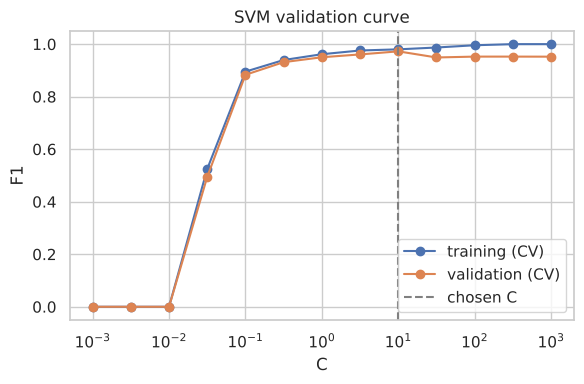

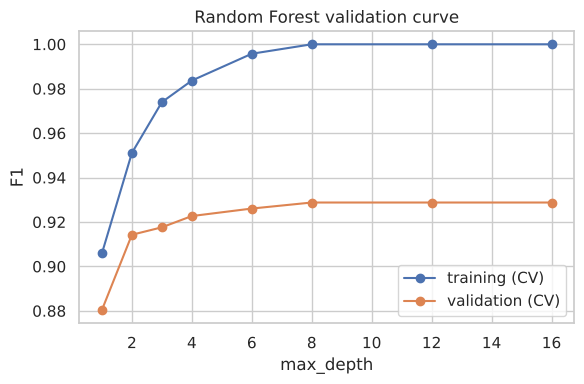

In [18]:
# Validation curve: SVM regularisation strength C (small C -> underfit, very large C -> overfit)
svm_best = tuned["SVM (RBF)"]
Cs = np.logspace(-3, 3, 13)
tr, va = validation_curve(svm_best, X_train, y_train, param_name="clf__C", param_range=Cs, cv=cv, scoring="f1", n_jobs=-1)
plt.figure(figsize=(6, 4))
plt.semilogx(Cs, tr.mean(1), "o-", label="training (CV)"); plt.semilogx(Cs, va.mean(1), "o-", label="validation (CV)")
plt.axvline(svm_best.get_params()["clf__C"], ls="--", c="grey", label="chosen C")
plt.xlabel("C"); plt.ylabel("F1"); plt.title("SVM validation curve"); plt.legend()
save("06_svm_validation_curve")

# Validation curve: Random Forest max_depth
depths = [1, 2, 3, 4, 6, 8, 12, 16]
rf_best = tuned["Random Forest"]
tr, va = validation_curve(rf_best, X_train, y_train, param_name="clf__max_depth", param_range=depths, cv=cv, scoring="f1", n_jobs=-1)
plt.figure(figsize=(6, 4))
plt.plot(depths, tr.mean(1), "o-", label="training (CV)"); plt.plot(depths, va.mean(1), "o-", label="validation (CV)")
plt.xlabel("max_depth"); plt.ylabel("F1"); plt.title("Random Forest validation curve"); plt.legend()
save("07_rf_validation_curve")

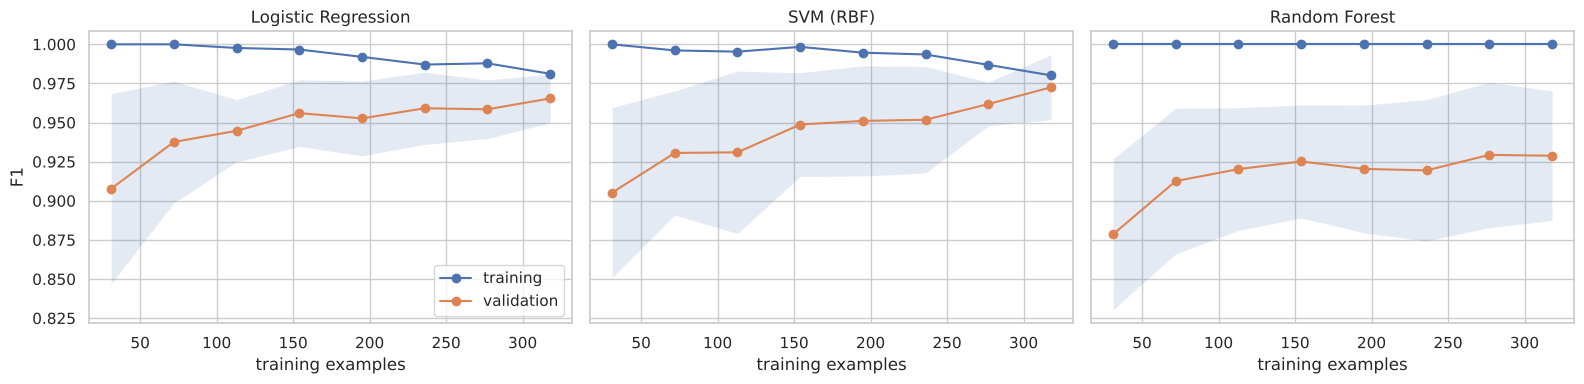

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, name in zip(axes, ["Logistic Regression", "SVM (RBF)", "Random Forest"]):
    sizes, tr, va = learning_curve(tuned[name], X_train, y_train, cv=cv, scoring="f1", train_sizes=np.linspace(0.1, 1, 8), n_jobs=-1)
    ax.plot(sizes, tr.mean(1), "o-", label="training"); ax.plot(sizes, va.mean(1), "o-", label="validation")
    ax.fill_between(sizes, va.mean(1) - va.std(1), va.mean(1) + va.std(1), alpha=.15)
    ax.set_title(name); ax.set_xlabel("training examples")
axes[0].set_ylabel("F1"); axes[0].legend()
save("08_learning_curves_traditional")

### 4.2 Neural Network — training and validation curves
The tuned architecture is retrained epoch by epoch (`partial_fit`) so training and validation loss/accuracy can be tracked. For comparison, the same network **without** regularisation and without early stopping is trained for many epochs to show what overfitting looks like on this data.

In [20]:
best_mlp = tuned["Neural Network (MLP)"].named_steps["clf"]
pp_nn = Pipeline(preprocessor()).fit(X_train, y_train)
Xtr_s, Xva_s = np.asarray(pp_nn.transform(X_train)), np.asarray(pp_nn.transform(X_val))

def train_curves(hidden, alpha, lr, epochs, patience=None):
    net = MLPClassifier(hidden_layer_sizes=hidden, alpha=alpha, learning_rate_init=lr, batch_size=32, random_state=SEED)
    hist = {k: [] for k in ["tr_loss", "va_loss", "tr_acc", "va_acc"]}
    best, best_ep, wait, best_state = np.inf, 0, 0, None
    for ep in range(epochs):
        net.partial_fit(Xtr_s, y_train.values, classes=[0, 1])
        ptr, pva = net.predict_proba(Xtr_s)[:, 1], net.predict_proba(Xva_s)[:, 1]
        hist["tr_loss"].append(log_loss(y_train, ptr)); hist["va_loss"].append(log_loss(y_val, pva))
        hist["tr_acc"].append(accuracy_score(y_train, ptr > .5)); hist["va_acc"].append(accuracy_score(y_val, pva > .5))
        if hist["va_loss"][-1] < best - 1e-4:
            best, best_ep, wait = hist["va_loss"][-1], ep, 0
            best_state = ([w.copy() for w in net.coefs_], [b.copy() for b in net.intercepts_])
        else:
            wait += 1
            if patience and wait >= patience: break
    return net, hist, best_ep, best_state

params = dict(hidden=best_mlp.hidden_layer_sizes, alpha=best_mlp.alpha, lr=best_mlp.learning_rate_init)
net_reg, h_reg, ep_reg, state_reg = train_curves(**params, epochs=400, patience=40)
net_ovf, h_ovf, ep_ovf, _ = train_curves(hidden=(128, 64), alpha=0.0, lr=1e-3, epochs=300)
print("Tuned NN:", params, "| best validation-loss epoch:", ep_reg + 1, "of", len(h_reg["tr_loss"]))
print("Unregularised NN: lowest validation loss at epoch", ep_ovf + 1, "| final train loss %.4f, final val loss %.4f" % (h_ovf["tr_loss"][-1], h_ovf["va_loss"][-1]))

Tuned NN: {'hidden': (64, 32), 'alpha': 0.01, 'lr': 0.001} | best validation-loss epoch: 12 of 52
Unregularised NN: lowest validation loss at epoch 7 | final train loss 0.0000, final val loss 0.5997


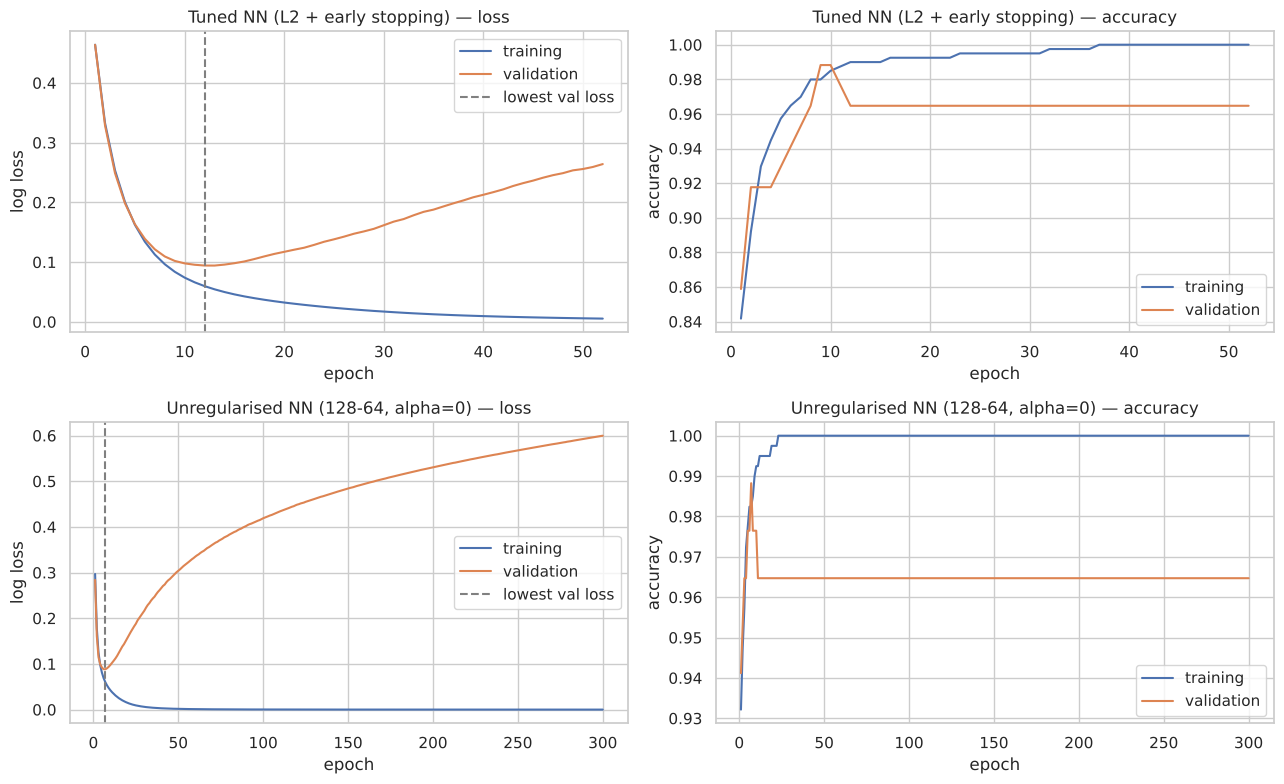

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for row, (h, ep, title) in enumerate([(h_reg, ep_reg, "Tuned NN (L2 + early stopping)"), (h_ovf, ep_ovf, "Unregularised NN (128-64, alpha=0)")]):
    e = np.arange(1, len(h["tr_loss"]) + 1)
    axes[row, 0].plot(e, h["tr_loss"], label="training"); axes[row, 0].plot(e, h["va_loss"], label="validation")
    axes[row, 0].axvline(ep + 1, ls="--", c="grey", label="lowest val loss")
    axes[row, 0].set_title(f"{title} — loss"); axes[row, 0].set_xlabel("epoch"); axes[row, 0].set_ylabel("log loss"); axes[row, 0].legend()
    axes[row, 1].plot(e, h["tr_acc"], label="training"); axes[row, 1].plot(e, h["va_acc"], label="validation")
    axes[row, 1].set_title(f"{title} — accuracy"); axes[row, 1].set_xlabel("epoch"); axes[row, 1].set_ylabel("accuracy"); axes[row, 1].legend()
save("09_nn_training_validation_curves")

In [22]:
# Use the weights from the epoch with the lowest validation loss (early stopping) as the final NN
net_reg.coefs_, net_reg.intercepts_ = state_reg
final_nn = Pipeline(list(pp_nn.steps) + [("clf", net_reg)])
tuned["Neural Network (MLP)"] = final_nn
print("Final NN  train F1: %.4f | validation F1: %.4f" % (f1_score(y_train, final_nn.predict(X_train)), f1_score(y_val, final_nn.predict(X_val))))

Final NN  train F1: 0.9864 | validation F1: 0.9508


## Stage 5 — Final Evaluation on the Test Set
Metrics: **Recall** (sensitivity for malignant — a missed cancer is the costliest error), **Precision**, **F1**, **ROC-AUC** (threshold-independent ranking quality), plus Accuracy and confusion matrices for completeness.

In [23]:
res = []
for name, m in tuned.items():
    p = m.predict_proba(X_test)[:, 1]; yhat = (p >= .5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, yhat).ravel()
    res.append({"model": name, "Accuracy": accuracy_score(y_test, yhat), "Precision": precision_score(y_test, yhat),
                "Recall": recall_score(y_test, yhat), "F1": f1_score(y_test, yhat), "ROC-AUC": roc_auc_score(y_test, p),
                "FN (missed malignant)": fn, "FP (false alarm)": fp})
results = pd.DataFrame(res).set_index("model")
results.to_csv("results_test.csv")
results.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC,FN (missed malignant),FP (false alarm)
model,,,,,,,
Logistic Regression,0.9651,0.9677,0.9375,0.9524,0.9988,2,1
SVM (RBF),0.9767,1.0000,0.9375,0.9677,1.0000,2,0
Random Forest,0.9884,1.0000,0.9688,0.9841,0.9988,1,0
Neural Network (MLP),0.9767,1.0000,0.9375,0.9677,0.9988,2,0


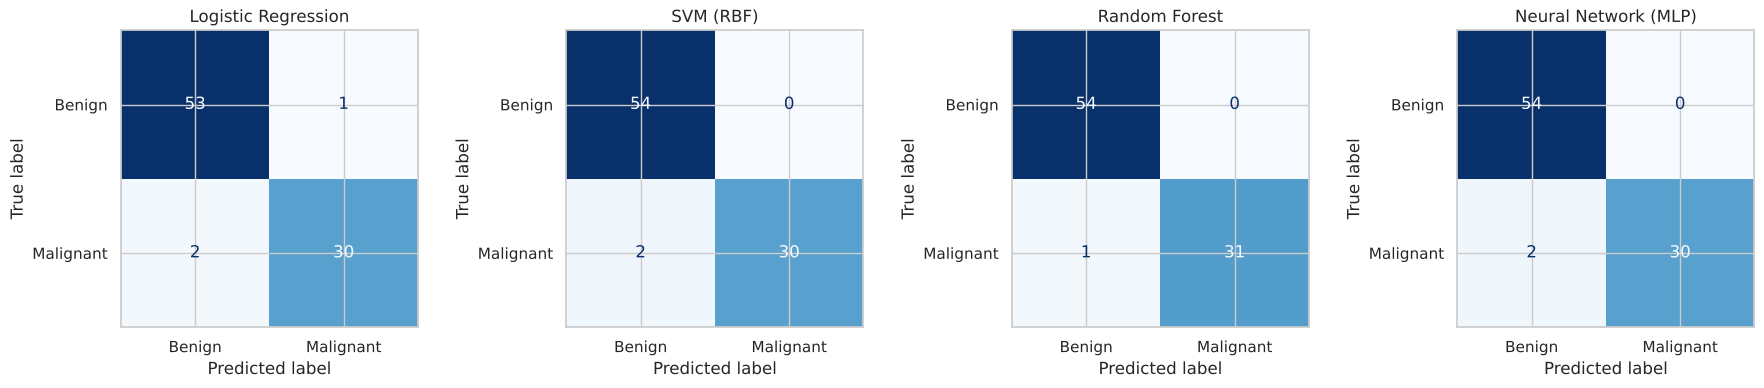

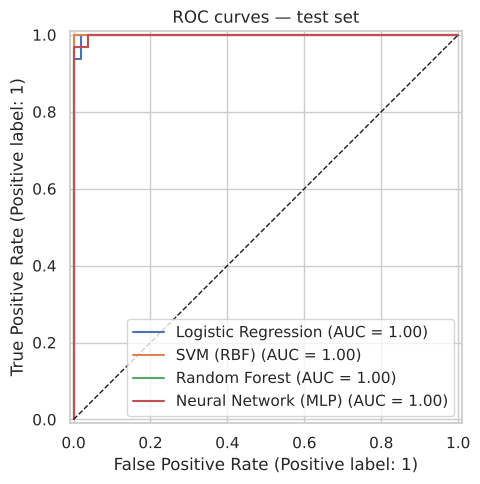

In [24]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, m) in zip(axes, tuned.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_test, y_test, display_labels=["Benign", "Malignant"], cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(name)
save("10_confusion_matrices")

fig, ax = plt.subplots(figsize=(6, 5))
for name, m in tuned.items():
    RocCurveDisplay.from_estimator(m, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set_title("ROC curves — test set")
save("11_roc_curves")

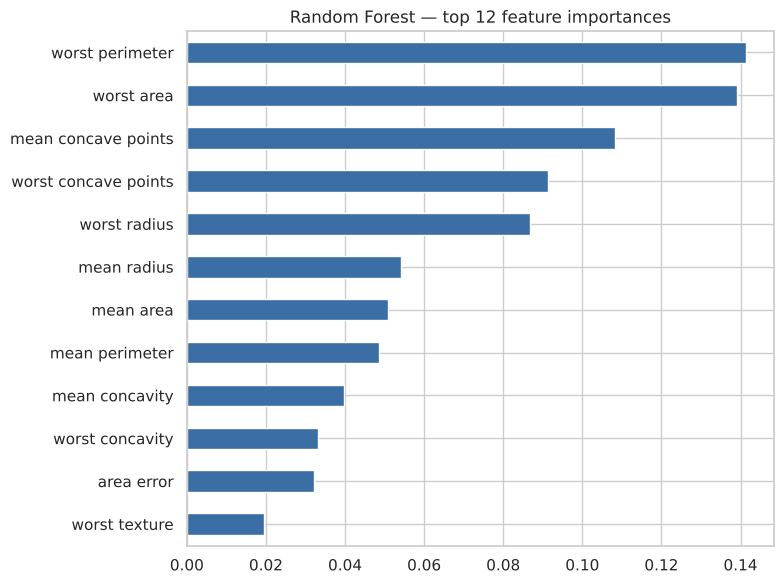

Logistic Regression non-zero coefficients: 23 of 23


radius error               2.270
mean radius                1.604
worst texture              1.371
mean concave points        1.239
worst symmetry             1.147
mean concavity             0.984
worst concavity            0.899
worst concave points       0.831
compactness error         -0.771
texture error             -0.502
mean texture               0.462
symmetry error            -0.433
fractal dimension error   -0.426
mean fractal dimension    -0.386
mean compactness          -0.386
mean symmetry             -0.315
worst smoothness           0.310
concave points error       0.309
worst compactness         -0.256
mean smoothness            0.238
smoothness error           0.231
concavity error           -0.192
worst fractal dimension    0.020
dtype: float64

In [25]:
fig, ax = plt.subplots(figsize=(8, 6))
imp = pd.Series(tuned["Random Forest"].named_steps["clf"].feature_importances_, index=X.columns).sort_values().tail(12)
imp.plot.barh(ax=ax, color="#3A6EA5"); ax.set_title("Random Forest — top 12 feature importances")
save("12_rf_feature_importance")

lr = tuned["Logistic Regression"]
kept = [c for c in X.columns if c not in lr.named_steps["corr"].drop_]
coef = pd.Series(lr.named_steps["clf"].coef_[0], index=kept)
print("Logistic Regression non-zero coefficients:", int((coef != 0).sum()), "of", len(coef))
coef[coef != 0].sort_values(key=abs, ascending=False).round(3)

In [26]:
for name, m in tuned.items():
    print("=" * 20, name); print(classification_report(y_test, m.predict(X_test), target_names=["Benign", "Malignant"], digits=3))

==================== Logistic Regression
              precision    recall  f1-score   support

      Benign      0.964     0.981     0.972        54
   Malignant      0.968     0.938     0.952        32

    accuracy                          0.965        86
   macro avg      0.966     0.959     0.962        86
weighted avg      0.965     0.965     0.965        86

==================== SVM (RBF)
              precision    recall  f1-score   support

      Benign      0.964     1.000     0.982        54
   Malignant      1.000     0.938     0.968        32

    accuracy                          0.977        86
   macro avg      0.982     0.969     0.975        86
weighted avg      0.978     0.977     0.977        86

==================== Random Forest
              precision    recall  f1-score   support

      Benign      0.982     1.000     0.991        54
   Malignant      1.000     0.969     0.984        32

    accuracy                          0.988        86
   macro avg      0.9

## Summary
The comparison table above is the final test-set result. See the project report for the discussion of which model is most suitable and why.